# IDEALE: sistema inteligente para la venta de vehículos usados — datos, modelos y resultados

**Cuaderno de apoyo del informe final de la asignatura *Aplicación de la Inteligencia Artificial***

Universidad Cooperativa de Colombia · Campus Villavicencio · 2026

| | |
|---|---|
| **Proyecto** | Sistema inteligente que estima el valor comercial de un vehículo usado y sugiere precios de compra y de venta para una compraventa |
| **Autores** | Brajhan Andres Quintero (886750) · Cristian Felipe Baquero Fuentes (844328) · Viviana Aldereter Conde (785841) |
| **Docente** | Mgs. Yomaria Guzmán Paredes |
| **Documento asociado** | `Informe_IDEALE.docx` (informe en formato APA) y `Presentacion_IDEALE.pptx` |
| **Metodología** | CRISP-DM |

## Propósito de este cuaderno

El informe describe IDEALE y presenta sus resultados con tablas y figuras. Este cuaderno es la **evidencia ejecutable** de esas cifras: carga los datos reales del proyecto, los explora, **reproduce el entrenamiento y la evaluación** de los modelos y explica, para cada gráfica, **qué muestra, por qué se eligió ese tipo de gráfica y qué decisión del proyecto respalda**.

Cada cifra importante se **recalcula** aquí y se **compara** con la que quedó registrada por el entrenamiento del proyecto (`modelo/` y `evidencias/`). La sección 8 reúne todas esas comprobaciones en una sola tabla.

El cuaderno cubre cinco bloques:

1. **Los datos.** Los 1.000 vehículos del proyecto: qué columnas tienen, cómo se distribuyen y qué relación tienen con el precio.
2. **El precio.** Cómo se generó (es sintético) y por qué se modela en escala logarítmica.
3. **Los modelos de Python.** Una línea base, cuatro algoritmos de regresión y el experimento con distinta cantidad de nodos de la red neuronal.
4. **La red neuronal de Weka.** Los resultados de clasificación por segmento de precio, recalculados desde las matrices de confusión.
5. **El uso del modelo.** Cómo responde el modelo final a casos concretos y a cambios de año y kilometraje.

## Cómo ejecutar este cuaderno

* **Requisitos:** el entorno del proyecto (`venv`) con las librerías de `requirements.txt` (`pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib`, `joblib`). Para abrirlo se puede usar Visual Studio Code (extensión *Jupyter*) o Jupyter Notebook, eligiendo el kernel del `venv`.
* **Ubicación:** el cuaderno debe estar en la carpeta `proyecto_venta_carros/`, junto a `app.py`. Solo **lee** archivos del proyecto: no modifica el modelo publicado ni las evidencias.
* **Orden:** ejecute las celdas de arriba hacia abajo (*Run All*). Tarda alrededor de **1 a 2 minutos**; la parte más lenta es la validación cruzada de la sección 5.
* **Convenciones:** en el texto se usa la coma como separador decimal y el punto para los miles, como en el informe. Los precios están en pesos colombianos (COP); «M» significa millones.

## Contenido

0. Configuración, semilla y funciones de apoyo
1. Comprensión del negocio
2. Comprensión de los datos
3. El precio de los vehículos
4. Preparación de los datos
5. Modelado y evaluación en Python
6. Red neuronal en Weka
7. Uso del modelo final
8. Resumen de resultados y comprobación de cifras
9. Limitaciones y trabajo futuro
10. Conclusiones
* Anexo A. Glosario

# 0. Configuración, semilla y funciones de apoyo

**Objetivo de la sección.** Dejar listo el entorno: cargar las librerías, fijar la semilla aleatoria para que los resultados se repitan, localizar los archivos del proyecto, comprobar que los datos son los mismos con los que se entrenó y definir las utilidades de formato y de gráficas.

### 0.1 Librerías y semilla

Se usa la misma semilla del proyecto (`SEED = 42`, definida en `pipeline/config.py`). Con la misma semilla, las mismas versiones de las librerías y los mismos datos, la división 80/20 y la validación cruzada producen exactamente los mismos grupos y, por tanto, las mismas cifras.

In [1]:
import hashlib
import json
import platform
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy.io import arff

warnings.filterwarnings("ignore")

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "pipeline"))   # para reutilizar el código del entrenamiento

from config import SEED, ANIO_ACTUAL         # noqa: E402  (mismos parámetros que el proyecto)
np.random.seed(SEED)

print("Python       :", platform.python_version())
print("numpy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scipy        :", scipy.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)
print("Semilla      :", SEED, "| Año de referencia:", ANIO_ACTUAL)

Python       : 3.11.9
numpy        : 2.4.6
pandas       : 3.0.6
scipy        : 1.17.1
scikit-learn : 1.9.1
matplotlib   : 3.11.2
Semilla      : 42 | Año de referencia: 2026


### 0.2 Localización de los datos y huella de integridad

Se comprueba que existan los archivos del proyecto y se calcula la **huella SHA-256** del conjunto de datos. Esa huella quedó registrada en `evidencias/reporte_entrenamiento.md` cuando se entrenó el modelo. Si coinciden, este cuaderno está leyendo **exactamente los mismos datos** con los que se obtuvieron las cifras del informe.

In [2]:
ARCHIVOS = {
    "Dataset original (sin precio)": RAIZ / "data" / "original" / "dataset_ideale_weka_1000.arff",
    "Dataset con precio":            RAIZ / "data" / "dataset_ideale_con_precio.csv",
    "Modelo entrenado":              RAIZ / "modelo" / "modelo_ideale.joblib",
    "Catálogo del modelo":           RAIZ / "modelo" / "catalogo.json",
    "Comparación de modelos":        RAIZ / "modelo" / "comparacion_modelos.csv",
    "Experimento de nodos":          RAIZ / "evidencias" / "experimento_nodos_mlp.csv",
    "Validación cruzada":            RAIZ / "evidencias" / "validacion_cruzada.csv",
    "Predicciones de prueba":        RAIZ / "evidencias" / "predicciones_prueba.csv",
    "Resultados de Weka":            RAIZ / "evidencias" / "weka" / "resultados_weka_completos.csv",
    "Reporte de entrenamiento":      RAIZ / "evidencias" / "reporte_entrenamiento.md",
}
inventario = pd.DataFrame([
    {"Archivo": nombre, "Ruta": str(ruta.relative_to(RAIZ)), "Existe": ruta.exists(),
     "Tamaño (KB)": round(ruta.stat().st_size / 1024, 1) if ruta.exists() else None}
    for nombre, ruta in ARCHIVOS.items()
])
display(inventario)

huella = hashlib.sha256(ARCHIVOS["Dataset con precio"].read_bytes()).hexdigest()[:16]
reporte = ARCHIVOS["Reporte de entrenamiento"].read_text(encoding="utf-8")
huella_registrada = reporte.split("huella SHA-256: `")[1].split("`")[0]
print("Huella calculada :", huella)
print("Huella registrada:", huella_registrada)
print("✔ Los datos son los mismos del entrenamiento" if huella == huella_registrada
      else "⚠ Los datos cambiaron desde el último entrenamiento")

,Archivo,Ruta,Existe,Tamaño (KB)
0,Dataset original (sin precio),data\original\dataset_ideale_weka_1000.arff,True,64.7
1,Dataset con precio,data\dataset_ideale_con_precio.csv,True,64.0
2,Modelo entrenado,modelo\modelo_ideale.joblib,True,60.7
3,Catálogo del modelo,modelo\catalogo.json,True,1.7
4,Comparación de modelos,modelo\comparacion_modelos.csv,True,0.3
5,Experimento de nodos,evidencias\experimento_nodos_mlp.csv,True,0.7
6,Validación cruzada,evidencias\validacion_cruzada.csv,True,0.8
7,Predicciones de prueba,evidencias\predicciones_prueba.csv,True,14.5
8,Resultados de Weka,evidencias\weka\resultados_weka_completos.csv,True,0.4
9,Reporte de entrenamiento,evidencias\reporte_entrenamiento.md,True,2.7


Huella calculada : 3fd1171913b02e73
Huella registrada: 3fd1171913b02e73
✔ Los datos son los mismos del entrenamiento


### 0.3 Formato numérico, comprobaciones y estilo de las gráficas

* `pesos(v)` y `num(v, d)` escriben los números con coma decimal y punto de miles, como el informe.
* `comparar(nombre, calculado, registrado)` recalcula una cifra y la **compara con la registrada** por el entrenamiento. Imprime `✔ coincide` o `⚠ difiere` y la guarda para la tabla resumen de la sección 8. La tolerancia por defecto es muy pequeña (0,0005), porque con la misma semilla y las mismas versiones los resultados deben ser idénticos.
* **Paleta.** Se usan los colores institucionales del proyecto: azul marino para destacar el elemento principal de cada gráfica (el modelo ganador, la configuración elegida) y gris azulado para el resto. Así la vista va directo a lo importante.

In [3]:
def num(valor, decimales=2):
    texto = f"{valor:,.{decimales}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

def pesos(valor):
    return "$ " + num(valor, 0)

def millones(valor, decimales=2):
    return num(valor / 1e6, decimales) + " M"

COMPROBACIONES = []

def comparar(nombre, calculado, registrado, tol=0.0005):
    ok = bool(abs(float(calculado) - float(registrado)) <= tol * max(1, abs(float(registrado))))
    COMPROBACIONES.append({"Cifra": nombre, "Recalculada": float(calculado),
                           "Registrada": float(registrado), "Coincide": "✔" if ok else "⚠"})
    print(f"{'✔ coincide' if ok else '⚠ difiere'} | {nombre}: recalculada {num(calculado, 4)} · registrada {num(registrado, 4)}")

MARINO, AZUL, CLARO, GRIS = "#0f2742", "#1f4e79", "#a9bccf", "#5b6b7d"
SEGMENTOS = ["Barato", "Medio", "Caro"]
COLOR_SEGMENTO = {"Barato": "#3f7a5e", "Medio": "#a5793a", "Caro": "#8e3b46"}

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.formatter.use_locale": False,
})
formato_millones = matplotlib.ticker.FuncFormatter(lambda v, _: num(v / 1e6, 0))
%matplotlib inline
print("Utilidades listas.")

Utilidades listas.


**Conclusión de la sección.** El entorno queda configurado, la semilla fija y el conjunto de datos verificado por su huella: lo que se analiza aquí es lo mismo que se usó para entrenar el modelo del informe. A partir de este punto, cada cifra se *recalcula* o se *lee de los archivos de resultados*; ninguna se escribe a mano.

# 1. Comprensión del negocio

**Objetivo de la sección.** Recordar qué problema resuelve IDEALE, qué recibe y qué entrega, cómo viaja un vehículo por el sistema y qué objetivos se plantearon.

### 1.1 El problema

En una compraventa de vehículos usados hay que decidir rápido **cuánto ofrecer** por un carro y **a qué precio venderlo** después. El valor depende de muchos factores a la vez (marca, modelo, año, kilometraje, combustible, transmisión y estado) y normalmente se fija con la experiencia del vendedor o comparando anuncios. Una mala valoración hace perder dinero: si se compra caro, se reduce el margen; si se vende barato, se pierde ganancia; si se pide demasiado, el carro no se vende.

**Pregunta de investigación:** ¿cómo desarrollar un sistema basado en inteligencia artificial que estime el valor comercial de vehículos usados y apoye la fijación de precios de compra y venta?

### 1.2 Qué recibe y qué entrega el sistema

In [4]:
display(pd.DataFrame({
    "Entrada (lo que escribe el usuario)": ["Marca", "Modelo", "Año", "Kilometraje", "Combustible", "Transmisión", "Estado"],
    "Ejemplo": ["Toyota", "Corolla", "2018", "120.000 km", "Gasolina", "Automático", "Buen estado"],
}))
display(pd.DataFrame({
    "Salida (lo que entrega IDEALE)": ["Valor comercial estimado", "Precio de compra sugerido", "Precio de venta sugerido", "Segmento de precio"],
    "Cómo se calcula": ["Red neuronal entrenada", "Valor × (1 − margen)", "Valor × (1 + margen)", "Barato / Medio / Caro según el valor"],
}))

,Entrada (lo que escribe el usuario),Ejemplo
0,Marca,Toyota
1,Modelo,Corolla
2,Año,2018
3,Kilometraje,120.000 km
4,Combustible,Gasolina
5,Transmisión,Automático
6,Estado,Buen estado


,Salida (lo que entrega IDEALE),Cómo se calcula
0,Valor comercial estimado,Red neuronal entrenada
1,Precio de compra sugerido,Valor × (1 − margen)
2,Precio de venta sugerido,Valor × (1 + margen)
3,Segmento de precio,Barato / Medio / Caro según el valor


### 1.3 Cómo viaja un vehículo por el sistema

El siguiente diagrama resume las dos etapas del proyecto. **Por qué un diagrama de flujo:** el proceso tiene un orden fijo (primero se entrena, después se usa) y un diagrama lo muestra de un vistazo mejor que un párrafo. **Qué respalda:** que la aplicación no vuelve a entrenar el modelo cada vez; usa el archivo `modelo_ideale.joblib` que dejó el entrenamiento.

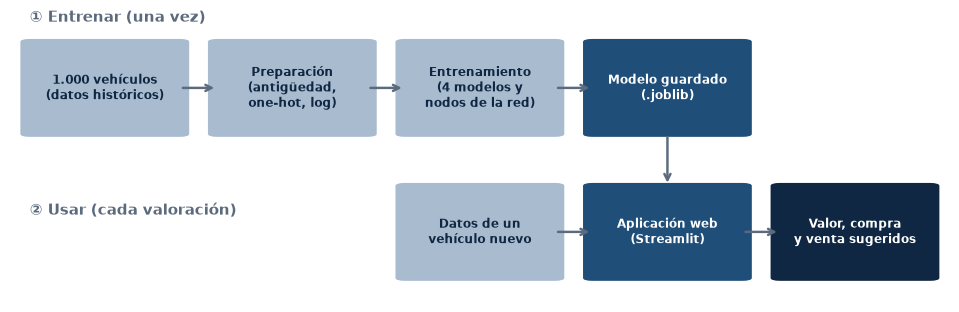

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.axis("off"); ax.grid(False)
cajas = [
    (0.02, 0.58, "1.000 vehículos\n(datos históricos)", CLARO),
    (0.22, 0.58, "Preparación\n(antigüedad,\none-hot, log)", CLARO),
    (0.42, 0.58, "Entrenamiento\n(4 modelos y\nnodos de la red)", CLARO),
    (0.62, 0.58, "Modelo guardado\n(.joblib)", AZUL),
    (0.62, 0.08, "Aplicación web\n(Streamlit)", AZUL),
    (0.82, 0.08, "Valor, compra\ny venta sugeridos", MARINO),
    (0.42, 0.08, "Datos de un\nvehículo nuevo", CLARO),
]
for x, y, texto, color in cajas:
    ax.add_patch(matplotlib.patches.FancyBboxPatch((x, y), 0.16, 0.32, boxstyle="round,pad=0.01",
                 facecolor=color, edgecolor="none", transform=ax.transAxes))
    ax.text(x + 0.08, y + 0.16, texto, ha="center", va="center", fontsize=8,
            color="white" if color != CLARO else MARINO, transform=ax.transAxes, fontweight="bold")
for (x1, y1), (x2, y2) in [((0.18, 0.74), (0.22, 0.74)), ((0.38, 0.74), (0.42, 0.74)), ((0.58, 0.74), (0.62, 0.74)),
                           ((0.70, 0.58), (0.70, 0.40)), ((0.58, 0.24), (0.62, 0.24)), ((0.78, 0.24), (0.82, 0.24))]:
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="->", color=GRIS, lw=1.6))
ax.text(0.02, 0.97, "① Entrenar (una vez)", transform=ax.transAxes, fontsize=10, color=GRIS, fontweight="bold")
ax.text(0.02, 0.30, "② Usar (cada valoración)", transform=ax.transAxes, fontsize=10, color=GRIS, fontweight="bold")
plt.show()

### 1.4 Objetivos del proyecto

| Objetivo | Descripción | Dónde se verifica en este cuaderno |
|---|---|---|
| **General** | Desarrollar un sistema que estime el valor comercial de un vehículo usado y genere recomendaciones de precio de compra y venta | Secciones 5 y 7 |
| **Específico 1** | Preparar y analizar un conjunto de datos de vehículos usados, identificando las características que influyen en su valor | Secciones 2, 3 y 4 |
| **Específico 2** | Entrenar y comparar modelos de IA, incluida una red neuronal en Python y en Weka, evaluando el efecto del número de nodos | Secciones 5 y 6 |
| **Específico 3** | Integrar el mejor modelo en una aplicación que sugiera precios de compra y venta | Sección 7 |

# 2. Comprensión de los datos

**Objetivo de la sección.** Conocer el conjunto de datos antes de entrenar: cuántos registros y columnas tiene, de qué tipo son, si hay datos faltantes o duplicados y cómo se distribuye cada variable.

### 2.1 Carga del archivo original

El archivo original del proyecto está en formato **ARFF** (el formato de Weka) y **no trae precio**. Se carga con `scipy.io.arff`, que lee las columnas de texto como bytes; por eso se decodifican a texto.

In [6]:
datos_arff, meta = arff.loadarff(ARCHIVOS["Dataset original (sin precio)"])
original = pd.DataFrame(datos_arff)
for col in original.select_dtypes("object"):
    original[col] = original[col].str.decode("utf-8")
original["anio"] = original["anio"].astype(int)
original["kilometraje"] = original["kilometraje"].astype(int)

print(f"Registros: {len(original)} | Columnas: {original.shape[1]}")
display(pd.DataFrame({"Tipo en ARFF": meta.types(), "Valores distintos": original.nunique().values},
                     index=meta.names()))

Registros: 1000 | Columnas: 7


,Tipo en ARFF,Valores distintos
marca,nominal,10
modelo,nominal,59
anio,numeric,25
combustible,nominal,2
transmision,nominal,2
kilometraje,numeric,955
estado,nominal,5


### 2.2 El conjunto de datos completo

Se carga el archivo **con precio** (`dataset_ideale_con_precio.csv`), que es el que usa el entrenamiento, y se muestran las primeras filas.

In [7]:
df = pd.read_csv(ARCHIVOS["Dataset con precio"])
print(f"{len(df)} vehículos · {df['marca'].nunique()} marcas · {df['modelo'].nunique()} modelos · "
      f"años {df['anio'].min()}–{df['anio'].max()}")
display(df.head(10).style.format({"precio": pesos, "kilometraje": lambda v: num(v, 0)}))

1000 vehículos · 10 marcas · 59 modelos · años 2000–2026


,marca,modelo,anio,combustible,transmision,kilometraje,estado,precio
0,Chevrolet,Captiva,2025,Diesel,Automatico,5.717,Mal estado,$ 90.400.000
1,Toyota,Prado,2008,Gasolina,Automatico,192.291,Medio estado,$ 72.400.000
2,Toyota,Fortuner,2005,Diesel,Automatico,286.700,Segunda mano,$ 54.000.000
3,Ford,Fiesta,2023,Gasolina,Manual,34.459,Segunda mano,$ 49.900.000
4,Volkswagen,Gol,2016,Gasolina,Manual,185.965,Mal estado,$ 9.600.000
5,Nissan,March,2014,Gasolina,Manual,79.550,Segunda mano,$ 12.800.000
6,Ford,Escape,2023,Gasolina,Automatico,29.000,Buen estado,$ 112.900.000
7,Toyota,Hilux,2013,Diesel,Automatico,219.325,Medio estado,$ 57.700.000
8,Mazda,Mazda 3,2018,Gasolina,Automatico,109.347,Medio estado,$ 40.500.000
9,Mazda,CX-30,2024,Gasolina,Automatico,34.485,Buen estado,$ 114.900.000


### 2.3 Calidad: datos faltantes, duplicados y valores imposibles

Antes de entrenar hay que saber si el conjunto tiene problemas. Se revisan los valores faltantes, las filas duplicadas y los valores que no tienen sentido (kilometraje negativo o precio cero), que son exactamente los filtros que aplica `paso2_entrenar_modelo.py`.

In [8]:
calidad = pd.DataFrame({
    "Revisión": ["Valores faltantes", "Filas duplicadas", "Kilometraje negativo", "Precio ≤ 0",
                 "Vehículos 'Nuevo 0 km' con más de 100 km"],
    "Cantidad": [int(df.isna().sum().sum()), int(df.duplicated().sum()), int((df["kilometraje"] < 0).sum()),
                 int((df["precio"] <= 0).sum()),
                 int(((df["estado"] == "Nuevo 0 km") & (df["kilometraje"] > 100)).sum())],
})
display(calidad)

,Revisión,Cantidad
0,Valores faltantes,0
1,Filas duplicadas,0
2,Kilometraje negativo,0
3,Precio ≤ 0,0
4,Vehículos 'Nuevo 0 km' con más de 100 km,0


El conjunto no tiene faltantes, duplicados ni valores imposibles en kilometraje o precio, así que la limpieza no elimina ningún registro (1.000 de 1.000). Sí aparecen vehículos marcados como «Nuevo 0 km» con kilometraje, una incoherencia propia del archivo original. No se eliminaron para no perder datos, pero la aplicación **sí valida este caso** cuando el usuario ingresa un vehículo (ver sección 7).

### 2.4 Vehículos por marca

**Qué muestra:** cuántos vehículos hay de cada marca. **Por qué barras horizontales:** son categorías con nombre, y las barras horizontales permiten leer los nombres sin rotarlos y comparar longitudes de un vistazo. **Qué respalda:** que el conjunto está **balanceado** entre marcas (ninguna domina), de modo que el modelo no aprende solo de una marca.

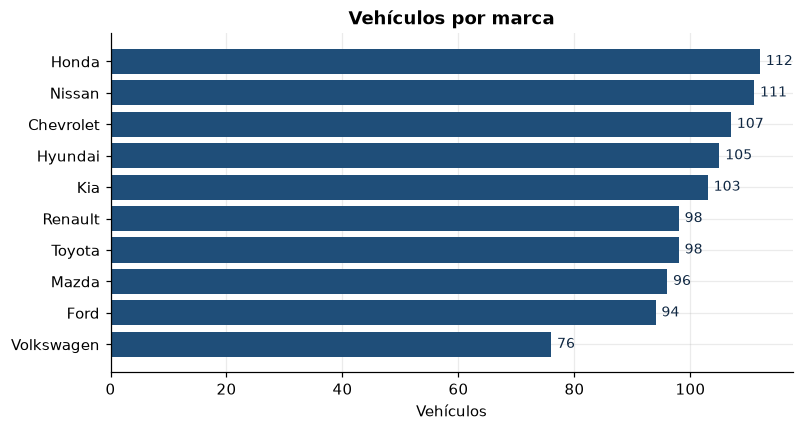

Mínimo: 76 (Volkswagen) · Máximo: 112 (Honda)


In [9]:
conteo = df["marca"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(conteo.index, conteo.values, color=AZUL)
for i, v in enumerate(conteo.values):
    ax.text(v + 1, i, str(v), va="center", fontsize=9, color=MARINO)
ax.set_title("Vehículos por marca"); ax.set_xlabel("Vehículos")
plt.show()
print(f"Mínimo: {conteo.min()} ({conteo.idxmin()}) · Máximo: {conteo.max()} ({conteo.idxmax()})")

### 2.5 Distribución del año y del kilometraje

**Qué muestra:** cuántos vehículos hay de cada año y de cada rango de kilometraje. **Por qué histogramas:** son variables numéricas continuas, y el histograma muestra dónde se concentran los datos y si hay valores extremos. **Qué respalda:** el rango en el que el modelo puede estimar con confianza; fuera de esos valores (por ejemplo, más de 500.000 km) no hay ejemplos de los que aprender.

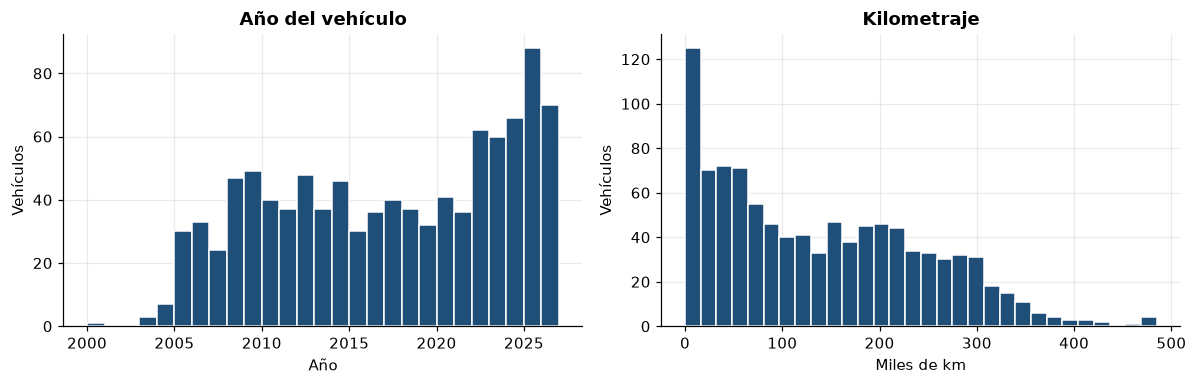

Año: mediana 2017 · Kilometraje: mediana 121.894 km, máximo 485.062 km


In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.hist(df["anio"], bins=range(df["anio"].min(), df["anio"].max() + 2), color=AZUL, edgecolor="white")
a1.set_title("Año del vehículo"); a1.set_xlabel("Año"); a1.set_ylabel("Vehículos")
a2.hist(df["kilometraje"] / 1000, bins=30, color=AZUL, edgecolor="white")
a2.set_title("Kilometraje"); a2.set_xlabel("Miles de km"); a2.set_ylabel("Vehículos")
plt.tight_layout(); plt.show()
print(f"Año: mediana {int(df['anio'].median())} · Kilometraje: mediana {num(df['kilometraje'].median(), 0)} km, "
      f"máximo {num(df['kilometraje'].max(), 0)} km")

### 2.6 Variables categóricas: combustible, transmisión y estado

**Qué muestra:** la proporción de cada categoría. **Por qué barras:** permiten comparar pocas categorías con precisión (mejor que un gráfico de torta, donde los ángulos son difíciles de comparar). **Qué respalda:** que hay ejemplos suficientes de cada categoría; el diésel es minoría (alrededor de 1 de cada 5 vehículos), lo cual es razonable para el mercado de carros particulares.

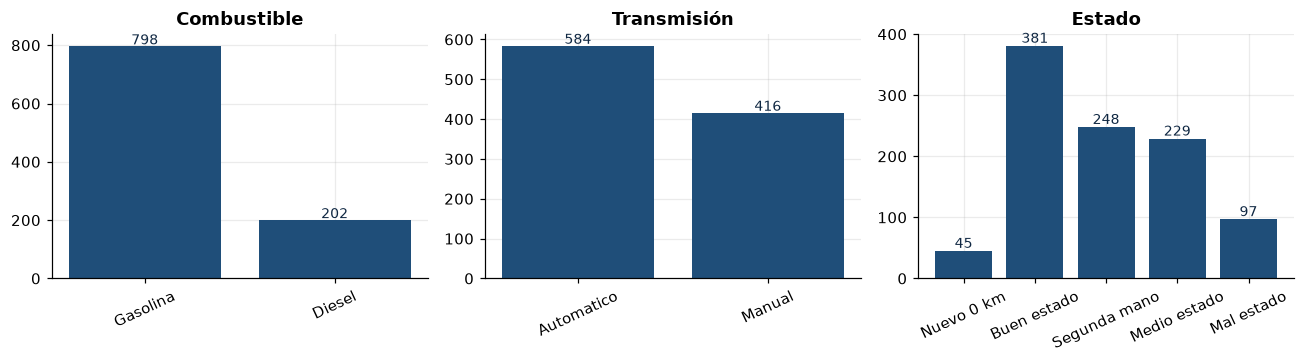

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
orden_estado = ["Nuevo 0 km", "Buen estado", "Segunda mano", "Medio estado", "Mal estado"]
for ax, col, orden in [(axs[0], "combustible", None), (axs[1], "transmision", None), (axs[2], "estado", orden_estado)]:
    c = df[col].value_counts()
    c = c.reindex(orden) if orden else c
    ax.bar(c.index, c.values, color=AZUL)
    for i, v in enumerate(c.values):
        ax.text(i, v + 5, str(v), ha="center", fontsize=9, color=MARINO)
    ax.set_title(col.capitalize().replace("Transmision", "Transmisión")); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

### 2.7 Relación entre año y kilometraje

**Qué muestra:** cada punto es un vehículo, con su año y su kilometraje. **Por qué un diagrama de dispersión:** es la forma natural de ver si dos variables numéricas están relacionadas. **Qué respalda:** que los carros más viejos tienden a tener más kilómetros (correlación negativa entre año y km). Como estas dos variables están relacionadas, el modelo debe usarlas juntas; por eso la aplicación también avisa cuando el kilometraje es poco creíble para la edad del vehículo.

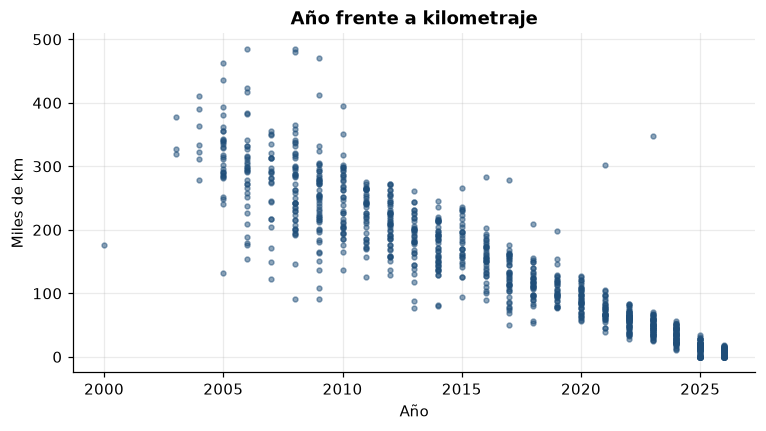

Correlación año–kilometraje: -0,92


In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df["anio"], df["kilometraje"] / 1000, s=10, alpha=0.5, color=AZUL)
ax.set_title("Año frente a kilometraje"); ax.set_xlabel("Año"); ax.set_ylabel("Miles de km")
plt.show()
print(f"Correlación año–kilometraje: {num(df['anio'].corr(df['kilometraje']), 2)}")

**Conclusión de la sección.** El conjunto tiene 1.000 vehículos de 10 marcas y 59 modelos, sin faltantes ni duplicados, con marcas balanceadas y un rango amplio de años (2000–2026) y kilometrajes. Las variables disponibles (marca, modelo, año, kilometraje, combustible, transmisión y estado) son las que se identificaron en el **objetivo específico 1** como determinantes del valor. El cilindraje y la potencia, mencionados en la propuesta inicial, **no están en los datos**.

# 3. El precio de los vehículos

**Objetivo de la sección.** Explicar de dónde sale el precio, comprobar que se puede reproducir y analizar cómo se relaciona con las demás variables.

### 3.1 Cómo se generó el precio (es sintético)

El archivo original no trae precio, así que el proyecto lo **simula** en `pipeline/paso1_generar_precios.py` con una fórmula basada en cómo se deprecian los carros en Colombia:

$$\text{precio} = \text{precio nuevo del modelo} \times f_{\text{edad}} \times f_{\text{km}} \times f_{\text{estado}} \times f_{\text{transmisión}} \times f_{\text{combustible}} \times \text{ruido}$$

* $f_{\text{edad}}$: se pierde entre 9 % y 11,5 % por año (las camionetas y pickups conservan mejor su valor), con un piso del 18 %.
* $f_{\text{km}}$: compara el kilometraje con unos 15.000 km por año de uso.
* $f_{\text{estado}}$: de 1,00 (nuevo o buen estado) a 0,72 (mal estado).
* ruido: una variación aleatoria de alrededor del 6 %, que representa la negociación y las diferencias entre vendedores.
* Ningún vehículo vale menos de 5 millones y los precios se redondean a 100.000 pesos.

> **Importante:** los precios son **aproximados y simulados**, no precios reales de mercado. Por eso las métricas de los modelos son altas: el modelo aprende una fórmula conocida más un ruido pequeño.

### 3.2 Comprobación: la fórmula reproduce exactamente el precio del archivo

Se importa la función `calcular_precio` del propio proyecto y se recalcula el precio de los 1.000 vehículos con la misma semilla. Si los precios coinciden con los del archivo, queda demostrado que el conjunto de datos se generó con esa fórmula y que el proceso es **reproducible**.

In [13]:
from paso1_generar_precios import PRECIO_NUEVO, calcular_precio

rng = np.random.default_rng(SEED)
recalculado = original.apply(lambda fila: calcular_precio(fila, rng), axis=1).astype(int)
iguales = int((recalculado.values == df["precio"].values).sum())
print(f"Precios idénticos: {iguales} de {len(df)}")
print("✔ El precio se reproduce exactamente con la fórmula del proyecto" if iguales == len(df)
      else "⚠ Hay diferencias entre la fórmula y el archivo")
comparar("Precios reproducidos con la fórmula (de 1.000)", iguales, len(df))

Precios idénticos: 1000 de 1000
✔ El precio se reproduce exactamente con la fórmula del proyecto
✔ coincide | Precios reproducidos con la fórmula (de 1.000): recalculada 1.000,0000 · registrada 1.000,0000


### 3.3 Distribución del precio: escala normal y escala logarítmica

**Qué muestra:** a la izquierda, cuántos vehículos hay en cada rango de precio; a la derecha, lo mismo pero con el **logaritmo** del precio. **Por qué dos histogramas lado a lado:** permiten ver el efecto de la transformación sobre la misma variable. **Qué respalda:** la decisión de entrenar los modelos con el **logaritmo del precio**. En escala normal la distribución está muy cargada a la izquierda (muchos carros baratos y pocos muy caros); en escala logarítmica queda mucho más simétrica. Además, con el logaritmo el modelo trata el error en **proporción** al precio: equivocarse 5 millones en un carro de 10 millones pesa más que en uno de 200 millones.

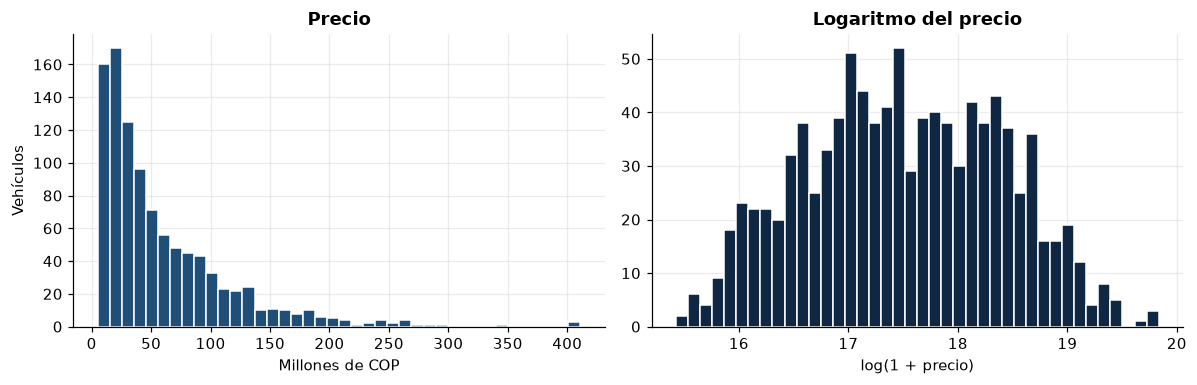

Asimetría del precio: 2,12 · del logaritmo: 0,01
Precio: mínimo 5,0 M · mediana 39,3 M · máximo 411,1 M


In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.hist(df["precio"], bins=40, color=AZUL, edgecolor="white")
a1.xaxis.set_major_formatter(formato_millones)
a1.set_title("Precio"); a1.set_xlabel("Millones de COP"); a1.set_ylabel("Vehículos")
a2.hist(np.log1p(df["precio"]), bins=40, color=MARINO, edgecolor="white")
a2.set_title("Logaritmo del precio"); a2.set_xlabel("log(1 + precio)")
plt.tight_layout(); plt.show()
print(f"Asimetría del precio: {num(df['precio'].skew(), 2)} · del logaritmo: {num(np.log1p(df['precio']).skew(), 2)}")
print(f"Precio: mínimo {millones(df['precio'].min(), 1)} · mediana {millones(df['precio'].median(), 1)} · "
      f"máximo {millones(df['precio'].max(), 1)}")

### 3.4 Precio según el estado del vehículo

**Qué muestra:** la distribución del precio para cada estado. **Por qué diagramas de caja:** resumen en una sola figura la mediana, la dispersión y los valores extremos de varios grupos, lo que permite compararlos. **Qué respalda:** que el **estado** influye en el precio, aunque se mezcla con otras variables: los carros «Nuevo 0 km» son los más caros porque además son los más recientes.

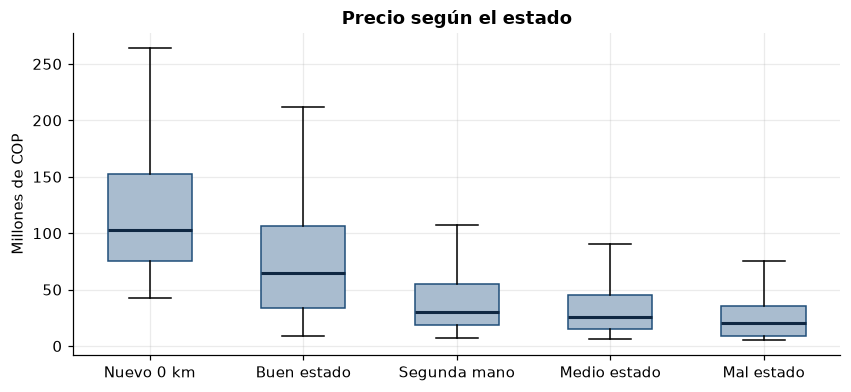

,Mediana del precio
estado,
Nuevo 0 km,"102,40 M"
Buen estado,"64,70 M"
Segunda mano,"30,35 M"
Medio estado,"25,90 M"
Mal estado,"20,00 M"


In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
grupos = [df.loc[df["estado"] == e, "precio"] for e in orden_estado]
caja = ax.boxplot(grupos, tick_labels=orden_estado, patch_artist=True, showfliers=False, widths=0.55)
for parche in caja["boxes"]:
    parche.set_facecolor(CLARO); parche.set_edgecolor(AZUL)
for med in caja["medians"]:
    med.set_color(MARINO); med.set_linewidth(2)
ax.yaxis.set_major_formatter(formato_millones)
ax.set_title("Precio según el estado"); ax.set_ylabel("Millones de COP")
plt.show()
display(df.groupby("estado")["precio"].median().reindex(orden_estado).map(millones).rename("Mediana del precio").to_frame())

### 3.5 Precio según la antigüedad

**Qué muestra:** el precio de cada vehículo frente a su antigüedad (2026 − año), en escala logarítmica. **Por qué dispersión con eje logarítmico:** la depreciación es un porcentaje por año, y en escala logarítmica un porcentaje constante se ve como una **línea recta**. **Qué respalda:** dos decisiones del proyecto: crear la variable **antigüedad** y modelar el **logaritmo del precio**, porque así la relación con la edad del carro se vuelve casi lineal. También se ve el «piso» de 5 millones en los carros más viejos, que es una parte **no lineal** que más adelante explica por qué la red neuronal supera a la regresión lineal.

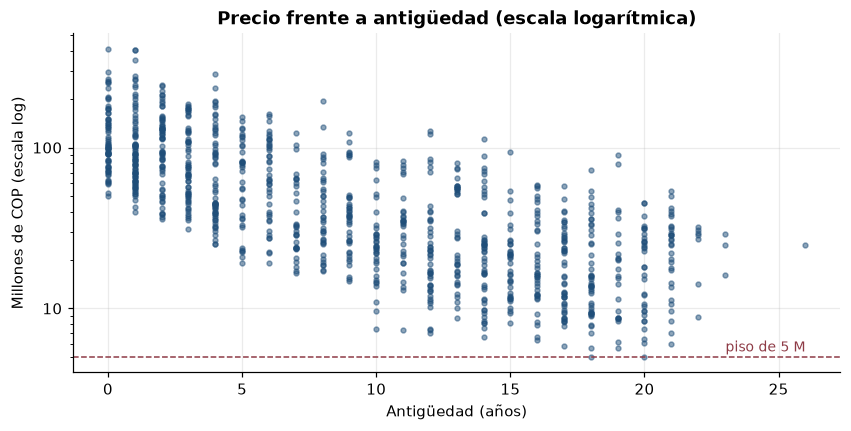

Correlación antigüedad–log(precio): -0,73


In [16]:
antig = ANIO_ACTUAL - df["anio"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(antig, df["precio"], s=10, alpha=0.5, color=AZUL)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(formato_millones)
ax.axhline(5_000_000, color=COLOR_SEGMENTO["Caro"], ls="--", lw=1)
ax.text(antig.max(), 5_400_000, "piso de 5 M", ha="right", color=COLOR_SEGMENTO["Caro"], fontsize=9)
ax.set_title("Precio frente a antigüedad (escala logarítmica)")
ax.set_xlabel("Antigüedad (años)"); ax.set_ylabel("Millones de COP (escala log)")
plt.show()
print(f"Correlación antigüedad–log(precio): {num(antig.corr(np.log1p(df['precio'])), 2)}")

### 3.6 Precio mediano por marca

**Qué muestra:** el precio mediano de los vehículos de cada marca. **Por qué la mediana y no el promedio:** unos pocos carros muy caros (por ejemplo, un Toyota Prado nuevo) subirían mucho el promedio; la mediana representa mejor el carro «típico». **Qué respalda:** que la **marca y el modelo** influyen en el precio, por eso son variables de entrada del modelo.

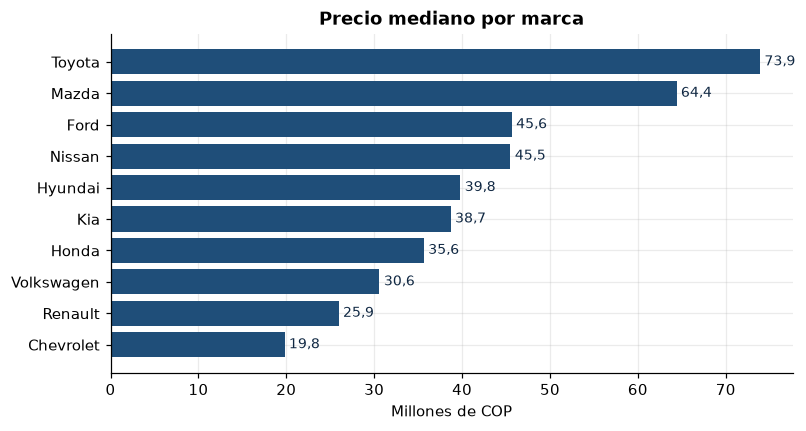

In [17]:
mediana_marca = df.groupby("marca")["precio"].median().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(mediana_marca.index, mediana_marca.values / 1e6, color=AZUL)
for i, v in enumerate(mediana_marca.values / 1e6):
    ax.text(v + 0.5, i, num(v, 1), va="center", fontsize=9, color=MARINO)
ax.set_title("Precio mediano por marca"); ax.set_xlabel("Millones de COP")
plt.show()

**Conclusión de la sección.** El precio es sintético pero **reproducible**: la fórmula del proyecto regenera los 1.000 precios exactamente. Su distribución es muy asimétrica y se vuelve simétrica con el logaritmo, y la relación con la antigüedad es casi lineal en esa escala, salvo el piso de 5 millones. Esto justifica dos decisiones de preparación: **crear la antigüedad** y **modelar el logaritmo del precio**.

# 4. Preparación de los datos

**Objetivo de la sección.** Mostrar cómo se transforman los datos antes de entrenar y cómo se dividen en entrenamiento y prueba. Se usan **las mismas funciones** de `pipeline/paso2_entrenar_modelo.py`, así que lo que se ve aquí es exactamente lo que hace el entrenamiento.

### 4.1 Limpieza y nueva variable: antigüedad

In [18]:
import paso2_entrenar_modelo as p2   # el mismo código del entrenamiento
%matplotlib inline

datos, info = p2.preparar_datos()
X = datos[p2.CATEGORICAS + p2.NUMERICAS]
y = datos["precio"]
print("Variables de entrada:", ", ".join(X.columns))
display(X.head())

Registros cargados: 1000
Registros tras limpieza: 1000 (eliminados: 0)
Variables de entrada: marca, modelo, combustible, transmision, estado, antiguedad, kilometraje


,marca,modelo,combustible,transmision,estado,antiguedad,kilometraje
0,Chevrolet,Captiva,Diesel,Automatico,Mal estado,1,5717
1,Toyota,Prado,Gasolina,Automatico,Medio estado,18,192291
2,Toyota,Fortuner,Diesel,Automatico,Segunda mano,21,286700
3,Ford,Fiesta,Gasolina,Manual,Segunda mano,3,34459
4,Volkswagen,Gol,Gasolina,Manual,Mal estado,10,185965


### 4.2 De texto a números: codificación *one-hot* y escalado

Los modelos solo entienden números. Por eso:

* Cada variable de texto se convierte en varias columnas de 0 y 1 (**one-hot**). Por ejemplo, «marca = Toyota» se vuelve una columna `marca_Toyota` con un 1 y las demás marcas con 0.
* La antigüedad y el kilometraje se **estandarizan** (se les resta la media y se dividen por la desviación), para que estén en escalas comparables. Esto es especialmente importante para la red neuronal.

La siguiente celda aplica ese preprocesamiento y muestra cuántas columnas recibe realmente el modelo.

In [19]:
prep = p2.pipe(p2.LinearRegression()).regressor.named_steps["prep"]
matriz = prep.fit_transform(X)
nombres = prep.get_feature_names_out()
resumen = pd.Series([n.split("__")[1].split("_")[0] if n.startswith("cat") else n.split("__")[1] for n in nombres]).value_counts()
print(f"Columnas originales: {X.shape[1]} → columnas que recibe el modelo: {matriz.shape[1]}")
display(resumen.rename("Columnas generadas").to_frame())

Columnas originales: 7 → columnas que recibe el modelo: 80


,Columnas generadas
modelo,59
marca,10
estado,5
combustible,2
transmision,2
antiguedad,1
kilometraje,1


### 4.3 División en entrenamiento (80 %) y prueba (20 %)

Se separan **800 vehículos para entrenar** y **200 para probar**. Los de prueba nunca se usan durante el entrenamiento: sirven para medir qué tan bien funciona el modelo con carros que no ha visto, como pasará en la compraventa real.

**Qué muestra la gráfica:** la distribución del precio en los dos grupos. **Por qué histogramas superpuestos y normalizados:** permiten ver si ambos grupos tienen la misma forma aunque tengan distinto tamaño. **Qué respalda:** que la prueba es **representativa**: si los dos grupos se parecen, el error medido en prueba es una buena estimación del error real.

Entrenamiento: 800 vehículos · Prueba: 200 vehículos


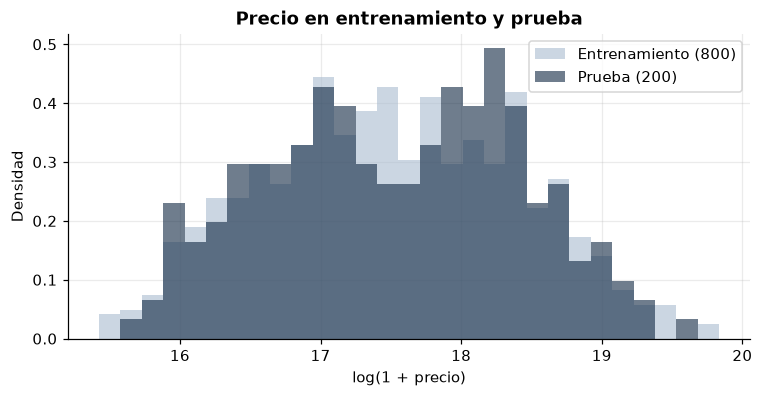

Mediana del precio · entrenamiento: 38,8 M · prueba: 42,0 M


In [20]:
from sklearn.model_selection import KFold, cross_val_score, train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f"Entrenamiento: {len(X_tr)} vehículos · Prueba: {len(X_te)} vehículos")

fig, ax = plt.subplots(figsize=(8, 3.6))
bordes = np.linspace(np.log1p(y).min(), np.log1p(y).max(), 30)
ax.hist(np.log1p(y_tr), bins=bordes, density=True, alpha=0.6, color=CLARO, label="Entrenamiento (800)")
ax.hist(np.log1p(y_te), bins=bordes, density=True, alpha=0.6, color=MARINO, label="Prueba (200)")
ax.set_title("Precio en entrenamiento y prueba"); ax.set_xlabel("log(1 + precio)"); ax.set_ylabel("Densidad")
ax.legend(); plt.show()
print(f"Mediana del precio · entrenamiento: {millones(y_tr.median(), 1)} · prueba: {millones(y_te.median(), 1)}")

**Conclusión de la sección.** Las 7 variables se transforman en las columnas numéricas que necesita el modelo, y los 1.000 vehículos se dividen en 800 de entrenamiento y 200 de prueba con distribuciones de precio muy parecidas. Con esto se cumple la fase de **preparación** de CRISP-DM y el **objetivo específico 1**.

# 5. Modelado y evaluación en Python

**Objetivo de la sección.** Reproducir el entrenamiento de los modelos, compararlos con una línea base, analizar el experimento de nodos de la red neuronal y entender dónde se equivoca el modelo final.

### Conceptos que se usan en esta sección

* **MAE (error absoluto medio):** cuántos pesos se equivoca el modelo en promedio. Es la métrica más fácil de explicar a la empresa.
* **RMSE:** parecido al MAE, pero castiga más los errores grandes.
* **R²:** qué proporción de la variación del precio explica el modelo (1 = perfecto, 0 = no mejor que adivinar el promedio).
* **Validación cruzada de 5 particiones:** se divide el entrenamiento en 5 partes, se entrena con 4 y se prueba con la restante, 5 veces. Si el resultado es parecido en las 5, no fue suerte.

### 5.1 La línea base: el modelo más simple posible

Antes de entrenar modelos de IA conviene saber cuánto se equivoca un «modelo» que no aprende nada: decir siempre el **precio mediano** del entrenamiento. Cualquier modelo útil debe superarlo por mucho.

In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

base = DummyRegressor(strategy="median").fit(X_tr, y_tr)
pred_base = base.predict(X_te)
mae_base = mean_absolute_error(y_te, pred_base)
print(f"Línea base (siempre {millones(np.median(y_tr), 1)}): MAE = {millones(mae_base)} · R² = {num(r2_score(y_te, pred_base), 3)}")

Línea base (siempre 38,8 M): MAE = 37,76 M · R² = -0,149


### 5.2 Experimento: ¿cuántos nodos necesita la red neuronal?

Se entrena la red neuronal (perceptrón multicapa) con 7 configuraciones: 3, 5, 10, 20 y 50 nodos en una capa oculta, y 10 + 5 y 20 + 10 nodos en dos capas. La configuración se **elige con la validación cruzada** (solo datos de entrenamiento), no con el conjunto de prueba, para no sesgar la evaluación final. Esta celda ejecuta la misma función `experimento_nodos` del proyecto.

In [22]:
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)
inicio = time.perf_counter()
experimento, nodos_elegidos = p2.experimento_nodos(X_tr, X_te, y_tr, y_te, kfold)
print(f"Tiempo del experimento: {num(time.perf_counter() - inicio, 1)} s")
display(experimento.style.format({"R2 CV (media)": "{:.4f}", "R2 prueba": "{:.4f}",
                                  "MAE prueba (COP)": pesos, "Tiempo (s)": "{:.1f}"}))

registrado = pd.read_csv(ARCHIVOS["Experimento de nodos"], dtype={"Nodos": str})
for _, fila in experimento.iterrows():
    reg = registrado.loc[registrado["Nodos"] == fila["Nodos"]].iloc[0]
    comparar(f"R² validación cruzada · MLP {fila['Nodos']} nodos", fila["R2 CV (media)"], reg["R2 CV (media)"])

  MLP      3 nodos  R2 CV=0.9746  R2 prueba=0.9736  MAE=   4,490,730  (635 epocas, 1.8s)


  MLP      5 nodos  R2 CV=0.9754  R2 prueba=0.9782  MAE=   4,388,562  (553 epocas, 1.5s)


  MLP     10 nodos  R2 CV=0.9787  R2 prueba=0.9698  MAE=   5,036,763  (267 epocas, 0.9s)


  MLP     20 nodos  R2 CV=0.9818  R2 prueba=0.9791  MAE=   4,393,109  (387 epocas, 1.3s)


  MLP     50 nodos  R2 CV=0.9794  R2 prueba=0.9833  MAE=   4,189,422  (307 epocas, 1.2s)


  MLP   10,5 nodos  R2 CV=0.9798  R2 prueba=0.9832  MAE=   4,210,654  (376 epocas, 1.3s)


  MLP  20,10 nodos  R2 CV=0.9762  R2 prueba=0.9794  MAE=   4,081,873  (275 epocas, 0.9s)
  >>> Mejor red neuronal: 20 nodos

Tiempo del experimento: 38,0 s


,Nodos,Capas ocultas,R2 CV (media),R2 prueba,MAE prueba (COP),Epocas,Tiempo (s)
0,3,1,0.9746,0.9736,$ 4.490.730,635,1.8
1,5,1,0.9754,0.9782,$ 4.388.562,553,1.5
2,10,1,0.9787,0.9698,$ 5.036.763,267,0.9
3,20,1,0.9818,0.9791,$ 4.393.109,387,1.3
4,50,1,0.9794,0.9833,$ 4.189.422,307,1.2
5,"10,5",2,0.9798,0.9832,$ 4.210.654,376,1.3
6,"20,10",2,0.9762,0.9794,$ 4.081.873,275,0.9


✔ coincide | R² validación cruzada · MLP 3 nodos: recalculada 0,9746 · registrada 0,9746
✔ coincide | R² validación cruzada · MLP 5 nodos: recalculada 0,9754 · registrada 0,9754
✔ coincide | R² validación cruzada · MLP 10 nodos: recalculada 0,9787 · registrada 0,9787
✔ coincide | R² validación cruzada · MLP 20 nodos: recalculada 0,9818 · registrada 0,9818
✔ coincide | R² validación cruzada · MLP 50 nodos: recalculada 0,9794 · registrada 0,9794
✔ coincide | R² validación cruzada · MLP 10,5 nodos: recalculada 0,9798 · registrada 0,9798
✔ coincide | R² validación cruzada · MLP 20,10 nodos: recalculada 0,9762 · registrada 0,9762


**Qué muestra la gráfica:** el R² de validación cruzada de cada configuración (izquierda) y el error en pesos en el conjunto de prueba (derecha). **Por qué barras con la elegida resaltada:** se comparan pocas configuraciones con nombre, y el color oscuro señala la que se usa en el proyecto. **Qué respalda:** que **más nodos no siempre es mejor**: todas las configuraciones quedan muy cerca, y una segunda capa no aporta una mejora clara.

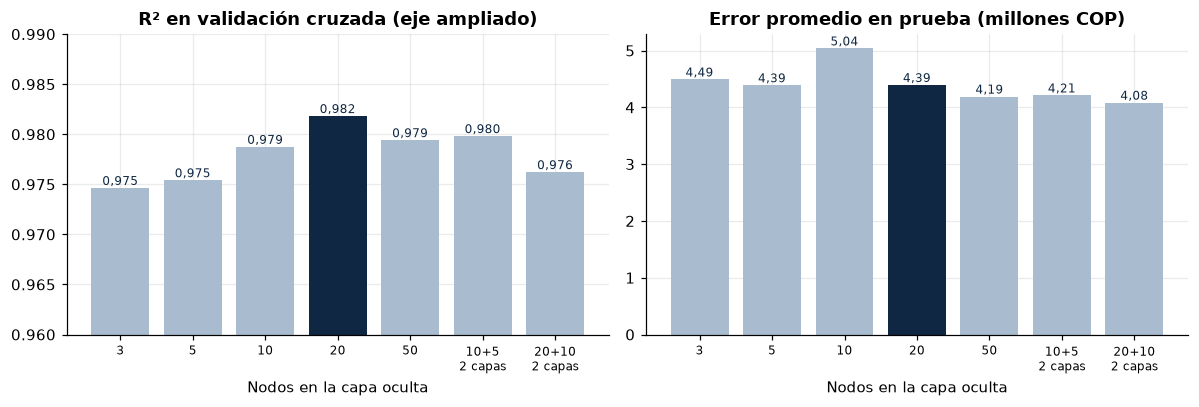

Configuración elegida por validación cruzada: 20 nodos


In [23]:
elegida = ",".join(map(str, nodos_elegidos))
colores = [MARINO if n == elegida else CLARO for n in experimento["Nodos"]]
etiquetas = [n if "," not in n else n.replace(",", "+") + "\n2 capas" for n in experimento["Nodos"]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.bar(etiquetas, experimento["R2 CV (media)"], color=colores)
a1.set_ylim(0.96, 0.99); a1.set_title("R² en validación cruzada (eje ampliado)")
a2.bar(etiquetas, experimento["MAE prueba (COP)"] / 1e6, color=colores)
a2.set_title("Error promedio en prueba (millones COP)")
for ax, col, f in [(a1, "R2 CV (media)", lambda v: num(v, 3)), (a2, "MAE prueba (COP)", lambda v: num(v / 1e6, 2))]:
    for i, v in enumerate(experimento[col]):
        ax.text(i, (v if col.startswith("R2") else v / 1e6), f(v), ha="center", va="bottom", fontsize=8, color=MARINO)
    ax.set_xlabel("Nodos en la capa oculta"); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
print(f"Configuración elegida por validación cruzada: {elegida} nodos")

### 5.3 Comparación de los cuatro modelos

Se entrenan los cuatro modelos del proyecto con los mismos datos (la red neuronal con la configuración elegida) y se comparan contra la línea base. Esta celda ejecuta la misma función `entrenar_y_evaluar` del entrenamiento y compara cada cifra con `modelo/comparacion_modelos.csv`.

In [24]:
tabla, cv, entrenados = p2.entrenar_y_evaluar(X_tr, X_te, y_tr, y_te, kfold, nodos_elegidos)
vista = tabla.copy()
vista.loc[len(vista)] = {"Modelo": "Línea base (mediana)", "MAE (COP)": mae_base,
                         "RMSE (COP)": np.sqrt(mean_squared_error(y_te, pred_base)),
                         "R2": r2_score(y_te, pred_base)}
display(vista.style.format({"MAE (COP)": pesos, "RMSE (COP)": pesos, "R2": "{:.4f}",
                            "R2 CV (media)": "{:.4f}", "R2 CV (desv.)": "{:.4f}", "Tiempo (s)": "{:.2f}"}, na_rep="—"))

registrada = pd.read_csv(ARCHIVOS["Comparación de modelos"])
for _, fila in tabla.iterrows():
    reg = registrada.loc[registrada["Modelo"] == fila["Modelo"]].iloc[0]
    comparar(f"R² prueba · {fila['Modelo']}", fila["R2"], reg["R2"])
    comparar(f"MAE prueba · {fila['Modelo']} (COP)", fila["MAE (COP)"], reg["MAE (COP)"])

Regresion lineal   MAE=   5,030,268  RMSE=   7,977,826  R2=0.9767  CV=0.9764±0.0033  (0.03s)


Random Forest      MAE=  12,767,220  RMSE=  21,864,970  R2=0.8247  CV=0.8127±0.0581  (0.62s)


Gradient Boosting  MAE=   9,439,103  RMSE=  15,461,474  R2=0.9124  CV=0.9090±0.0328  (0.63s)


Red neuronal (MLP) MAE=   4,393,109  RMSE=   7,551,002  R2=0.9791  CV=0.9818±0.0044  (1.31s)


,Modelo,MAE (COP),RMSE (COP),R2,R2 CV (media),R2 CV (desv.),Tiempo (s)
3,Red neuronal (MLP),$ 4.393.109,$ 7.551.002,0.9791,0.9818,0.0044,1.31
0,Regresion lineal,$ 5.030.268,$ 7.977.826,0.9767,0.9764,0.0033,0.03
2,Gradient Boosting,$ 9.439.103,$ 15.461.474,0.9124,0.9090,0.0328,0.63
1,Random Forest,$ 12.767.220,$ 21.864.970,0.8247,0.8127,0.0581,0.62
4,Línea base (mediana),$ 37.757.500,$ 55.982.596,-0.1490,—,—,—


✔ coincide | R² prueba · Red neuronal (MLP): recalculada 0,9791 · registrada 0,9791
✔ coincide | MAE prueba · Red neuronal (MLP) (COP): recalculada 4.393.108,9070 · registrada 4.393.108,9070
✔ coincide | R² prueba · Regresion lineal: recalculada 0,9767 · registrada 0,9767
✔ coincide | MAE prueba · Regresion lineal (COP): recalculada 5.030.267,6869 · registrada 5.030.267,6869
✔ coincide | R² prueba · Gradient Boosting: recalculada 0,9124 · registrada 0,9124
✔ coincide | MAE prueba · Gradient Boosting (COP): recalculada 9.439.103,0831 · registrada 9.439.103,0831
✔ coincide | R² prueba · Random Forest: recalculada 0,8247 · registrada 0,8247
✔ coincide | MAE prueba · Random Forest (COP): recalculada 12.767.220,3655 · registrada 12.767.220,3655


**Qué muestra la gráfica:** el error promedio de cada modelo y de la línea base. **Por qué barras horizontales ordenadas:** el orden de mejor a peor se lee de inmediato, y la línea base sirve de referencia. **Qué respalda:** la elección de la **red neuronal** como modelo de la aplicación: es la de menor error, seguida muy de cerca por la regresión lineal, y todos los modelos superan ampliamente a la línea base.

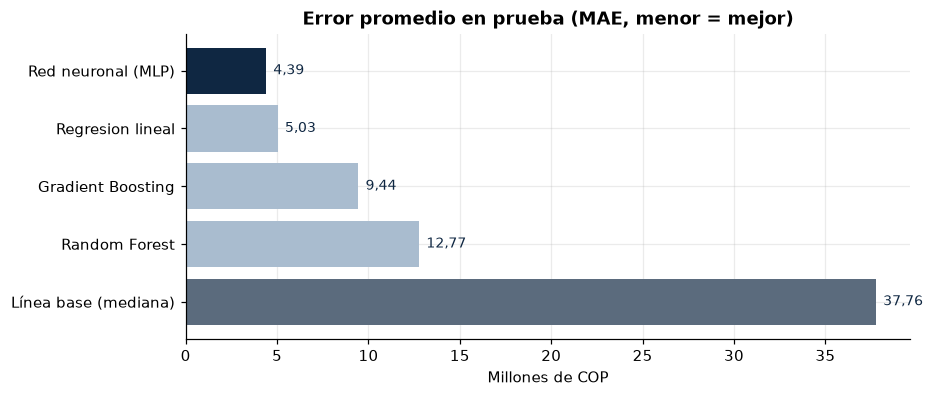

Mejor modelo: Red neuronal (MLP) · reduce el error de la línea base en 88,4 %


In [25]:
orden = vista.sort_values("MAE (COP)", ascending=False)
mejor = tabla.iloc[0]["Modelo"]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
colores = [MARINO if m == mejor else (GRIS if m.startswith("Línea") else CLARO) for m in orden["Modelo"]]
ax.barh(orden["Modelo"], orden["MAE (COP)"] / 1e6, color=colores)
for i, v in enumerate(orden["MAE (COP)"] / 1e6):
    ax.text(v + 0.4, i, num(v, 2), va="center", fontsize=9, color=MARINO)
ax.set_title("Error promedio en prueba (MAE, menor = mejor)"); ax.set_xlabel("Millones de COP")
plt.show()
print(f"Mejor modelo: {mejor} · reduce el error de la línea base en "
      f"{num((1 - tabla.iloc[0]['MAE (COP)'] / mae_base) * 100, 1)} %")

### 5.4 Estabilidad: validación cruzada por partición

**Qué muestra:** el R² de cada modelo en cada una de las 5 particiones. **Por qué líneas con puntos:** permiten seguir a cada modelo a través de las particiones y ver qué tan variable es. **Qué respalda:** que el resultado de la red neuronal y de la regresión lineal es **estable** (casi no cambia entre particiones), mientras que Random Forest varía mucho más.

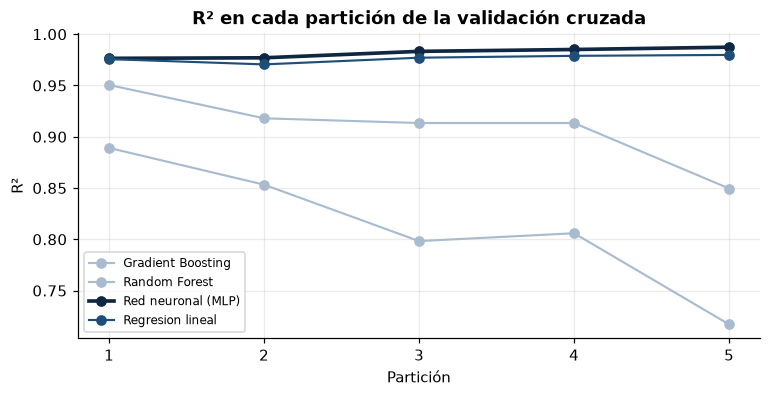

,R² medio,Desviación
Modelo,,
Gradient Boosting,0.9090,0.0367
Random Forest,0.8127,0.0650
Red neuronal (MLP),0.9818,0.0049
Regresion lineal,0.9764,0.0036


✔ coincide | R² medio validación cruzada · Red neuronal (MLP): recalculada 0,9818 · registrada 0,9818


In [26]:
pivote = cv.pivot(index="Particion", columns="Modelo", values="R2")
fig, ax = plt.subplots(figsize=(8, 3.6))
for modelo in pivote.columns:
    ax.plot(pivote.index, pivote[modelo], marker="o", lw=2.4 if modelo == mejor else 1.4,
            color=MARINO if modelo == mejor else CLARO if "lineal" not in modelo else AZUL, label=modelo)
ax.set_xticks(pivote.index); ax.set_xlabel("Partición"); ax.set_ylabel("R²")
ax.set_title("R² en cada partición de la validación cruzada"); ax.legend(fontsize=8, loc="lower left")
plt.show()
display(pivote.agg(["mean", "std"]).T.rename(columns={"mean": "R² medio", "std": "Desviación"}).style.format("{:.4f}"))
comparar("R² medio validación cruzada · Red neuronal (MLP)", pivote[mejor].mean(),
         pd.read_csv(ARCHIVOS["Validación cruzada"]).query("Modelo == @mejor")["R2"].mean())

### 5.5 Cómo aprendió la red neuronal: curva de pérdida

**Qué muestra:** el error de la red en cada época (vuelta de entrenamiento). **Por qué una curva:** el entrenamiento es un proceso en el tiempo y la curva muestra si la red aprendió y cuándo dejó de mejorar. **Qué respalda:** que la **parada temprana** (*early stopping*) funcionó: la pérdida baja rápido al principio, se estabiliza, y el entrenamiento se detiene solo cuando deja de mejorar, lo que evita que la red memorice los datos.

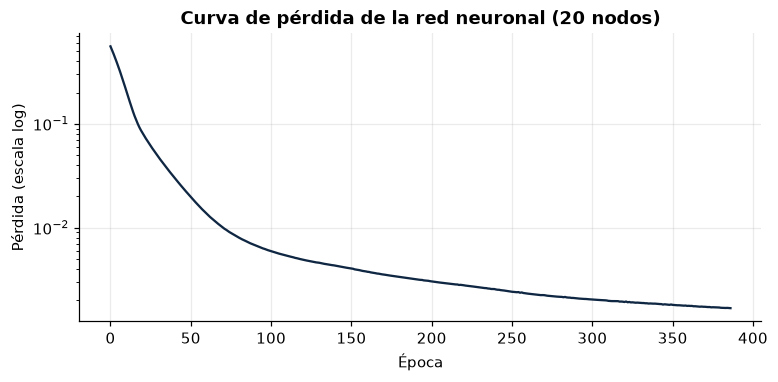

Épocas: 387 · capas: entrada 80 → oculta (20,) → salida 1 · pesos entrenados: 1641


In [27]:
red = entrenados[mejor][0].regressor_.named_steps["reg"].regressor_
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(red.loss_curve_, color=MARINO)
ax.set_yscale("log"); ax.set_title(f"Curva de pérdida de la red neuronal ({elegida} nodos)")
ax.set_xlabel("Época"); ax.set_ylabel("Pérdida (escala log)")
plt.show()
print(f"Épocas: {red.n_iter_} · capas: entrada {red.n_features_in_} → oculta {red.hidden_layer_sizes} → salida 1 · "
      f"pesos entrenados: {sum(w.size for w in red.coefs_) + sum(b.size for b in red.intercepts_)}")

### 5.6 Precio real frente a precio estimado

**Qué muestra:** cada punto es uno de los 200 vehículos de prueba; el eje horizontal es su precio real y el vertical, el que estimó la red. **Por qué dispersión con la diagonal:** si el modelo fuera perfecto, todos los puntos estarían sobre la línea; la distancia a la línea es el error. **Qué respalda:** que el modelo funciona en todo el rango de precios, desde carros de 5 millones hasta camionetas de más de 300 millones.

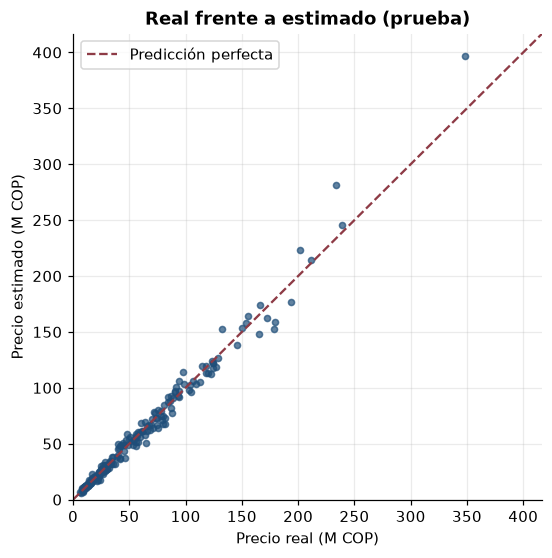

In [28]:
modelo_mejor, pred = entrenados[mejor]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_te / 1e6, pred / 1e6, s=16, alpha=0.7, color=AZUL)
lim = [0, max(y_te.max(), pred.max()) / 1e6 * 1.05]
ax.plot(lim, lim, "--", color=COLOR_SEGMENTO["Caro"], label="Predicción perfecta")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_title("Real frente a estimado (prueba)"); ax.set_xlabel("Precio real (M COP)"); ax.set_ylabel("Precio estimado (M COP)")
ax.legend(); plt.show()

### 5.7 ¿Qué tan grande es el error en porcentaje?

**Qué muestra:** cuántos vehículos de prueba tienen cada nivel de error porcentual. **Por qué un histograma con líneas de referencia:** muestra si los errores se concentran cerca de cero y qué tan seguido hay errores grandes; las líneas de 10 % y 20 % ayudan a leerlo. **Qué respalda:** la utilidad del modelo para la empresa: la mayoría de las estimaciones quedan a menos del 10 % del precio real.

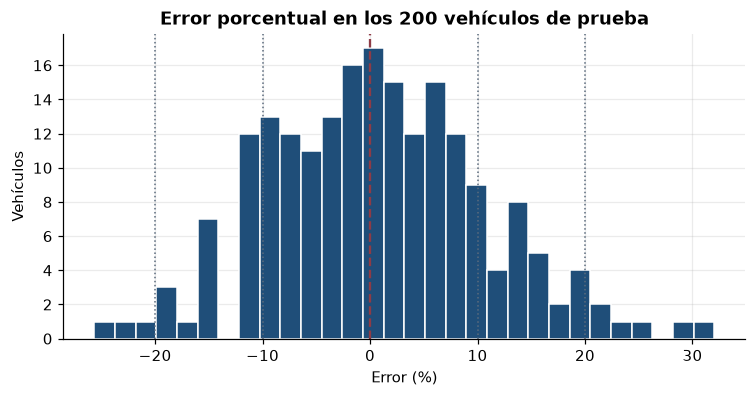

Error medio: 8,0 % · mediana: 6,6 % · menos de 10 %: 71,0 % de los vehículos · menos de 20 %: 95,0 %
✔ coincide | Vehículos de prueba con error < 20 % (%): recalculada 95,0000 · registrada 95,0000


In [29]:
error_pct = (pred - y_te.values) / y_te.values * 100
abs_pct = np.abs(error_pct)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(error_pct, bins=30, color=AZUL, edgecolor="white")
for v in (-20, -10, 10, 20):
    ax.axvline(v, color=GRIS, ls=":", lw=1)
ax.axvline(0, color=COLOR_SEGMENTO["Caro"], ls="--")
ax.set_title("Error porcentual en los 200 vehículos de prueba"); ax.set_xlabel("Error (%)"); ax.set_ylabel("Vehículos")
plt.show()
print(f"Error medio: {num(abs_pct.mean(), 1)} % · mediana: {num(np.median(abs_pct), 1)} % · "
      f"menos de 10 %: {num((abs_pct < 10).mean() * 100, 1)} % de los vehículos · "
      f"menos de 20 %: {num((abs_pct < 20).mean() * 100, 1)} %")
comparar("Vehículos de prueba con error < 20 % (%)", (abs_pct < 20).mean() * 100, 95.0, tol=0.01)

### 5.8 ¿Dónde se equivoca más el modelo?

**Qué muestra:** el error porcentual medio según la antigüedad del vehículo. **Por qué barras por grupos:** agrupar permite ver una tendencia que en los puntos sueltos no se nota. **Qué respalda:** una recomendación para la compraventa: el error crece en los carros de **más de 10 años** (ahí actúan el piso de 5 millones y el límite de depreciación de la fórmula), así que conviene revisarlos con más cuidado. El grupo más difícil es el de 11 a 15 años (10,7 %), y el de más de 15 años (9,1 %) también supera el error de los carros de hasta 10 años (6,5 % y 7,1 %).

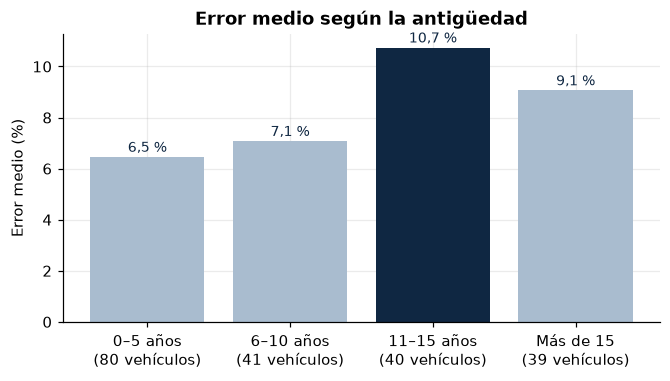

**Los 5 vehículos de prueba con mayor error:**

,marca,modelo,anio,kilometraje,estado,real,estimado,error_%
486,Mazda,Mazda 3,2011,271.829,Segunda mano,$ 17.100.000,$ 22.580.028,32.0 %
822,Hyundai,i10,2012,175.771,Medio estado,$ 8.100.000,$ 10.425.844,28.7 %
137,Toyota,Corolla,2006,272.066,Buen estado,$ 24.200.000,$ 17.995.411,-25.6 %
199,Volkswagen,Amarok,2007,150.062,Medio estado,$ 39.800.000,$ 49.660.116,24.8 %
578,Nissan,Frontier,2011,204.442,Segunda mano,$ 47.500.000,$ 58.321.279,22.8 %


In [30]:
prueba = datos.loc[X_te.index, ["marca", "modelo", "anio", "kilometraje", "estado"]].copy()
prueba["real"], prueba["estimado"], prueba["error_%"] = y_te.values, pred, error_pct
prueba["grupo"] = pd.cut(ANIO_ACTUAL - prueba["anio"], [-1, 5, 10, 15, 30],
                         labels=["0–5 años", "6–10 años", "11–15 años", "Más de 15"])
por_grupo = prueba.groupby("grupo", observed=True)["error_%"].apply(lambda e: e.abs().mean())
fig, ax = plt.subplots(figsize=(7, 3.4))
cantidad = prueba["grupo"].value_counts().reindex(por_grupo.index)
ax.bar(por_grupo.index.astype(str), por_grupo.values,
       color=[MARINO if v == por_grupo.max() else CLARO for v in por_grupo.values])
for i, v in enumerate(por_grupo.values):
    ax.text(i, v + 0.2, num(v, 1) + " %", ha="center", fontsize=9, color=MARINO)
ax.set_title("Error medio según la antigüedad"); ax.set_ylabel("Error medio (%)")
ax.set_xticks(range(len(por_grupo)), [f"{g}\n({n} vehículos)" for g, n in zip(por_grupo.index, cantidad.values)])
plt.show()
display(Markdown("**Los 5 vehículos de prueba con mayor error:**"))
display(prueba.reindex(prueba["error_%"].abs().sort_values(ascending=False).index).head(5)
        .drop(columns="grupo").style.format({"real": pesos, "estimado": pesos, "error_%": "{:.1f} %",
                                             "kilometraje": lambda v: num(v, 0)}))

**Conclusión de la sección.** La red neuronal con 20 nodos es el mejor modelo y el que usa la aplicación. Las cifras recalculadas coinciden con las del entrenamiento del proyecto. El experimento confirma que **más nodos o una segunda capa no mejoran de forma clara** y que el resultado es estable en la validación cruzada. El modelo se equivoca más en los carros de más de 10 años. Con esto se cumple el **objetivo específico 2** en su parte de Python.

# 6. Red neuronal en Weka

**Objetivo de la sección.** Analizar los resultados de la red neuronal entrenada en Weka Web y compararlos con la red de Python.

### 6.1 Por qué en Weka se clasificó por segmento

En Weka Web la red neuronal (*MultilayerPerceptron*) solo estaba disponible para **clasificación**. Por eso el precio se convirtió en tres **segmentos con la misma cantidad de vehículos** (terciles): barato, medio y caro. Además, se retiró la variable *modelo* (59 valores distintos), porque con ella el entrenamiento superaba el límite de 100 segundos de la plataforma. La siguiente celda recalcula los límites de los segmentos.

In [31]:
datos["segmento"], cortes = pd.qcut(datos["precio"], q=3, labels=SEGMENTOS, retbins=True)
display(pd.DataFrame({
    "Segmento": SEGMENTOS,
    "Desde": [millones(cortes[i], 1) for i in range(3)],
    "Hasta": [millones(cortes[i + 1], 1) for i in range(3)],
    "Vehículos": datos["segmento"].value_counts().reindex(SEGMENTOS).values,
}))

,Segmento,Desde,Hasta,Vehículos
0,Barato,"5,0 M","25,5 M",334
1,Medio,"25,5 M","63,5 M",333
2,Caro,"63,5 M","411,1 M",333


### 6.2 Resultados de Weka: exactitud recalculada desde la matriz de confusión

Los resultados se copiaron de Weka Web a `evidencias/weka/resultados_weka_completos.csv` (las capturas originales están en la misma carpeta). Aquí la **exactitud se recalcula** a partir de cada matriz de confusión (aciertos de la diagonal sobre el total) y se compara con la que informó Weka. Las filas de cada matriz suman los 1.000 vehículos, lo que confirma que Weka evaluó con **validación cruzada** (cada vehículo se clasificó una vez).

In [32]:
weka = pd.read_csv(ARCHIVOS["Resultados de Weka"], dtype={"hiddenLayers": str})

def matriz_weka(fila):
    return np.array([[fila[f"{r}->{p}"] for p in SEGMENTOS] for r in SEGMENTOS], dtype=int)

for _, fila in weka.iterrows():
    m = matriz_weka(fila)
    exactitud = np.trace(m) / m.sum() * 100
    comparar(f"Exactitud Weka · {fila['hiddenLayers']} nodos (%)", exactitud, fila["Accuracy (%)"], tol=0.0001)
    print(f"   vehículos en la matriz: {m.sum()}")
display(weka.iloc[:, :5].style.format("{:.2f}", subset=weka.columns[1:5]))

✔ coincide | Exactitud Weka · 3 nodos (%): recalculada 71,8000 · registrada 71,8000
   vehículos en la matriz: 1000
✔ coincide | Exactitud Weka · 5 nodos (%): recalculada 72,1000 · registrada 72,1000
   vehículos en la matriz: 1000
✔ coincide | Exactitud Weka · 10 nodos (%): recalculada 72,7000 · registrada 72,7000
   vehículos en la matriz: 1000
✔ coincide | Exactitud Weka · 10,5 nodos (%): recalculada 71,6000 · registrada 71,6000
   vehículos en la matriz: 1000


,hiddenLayers,Accuracy (%),Precision (%),Recall (%),F-Measure (%)
0,3,71.80,72.46,71.80,72.00
1,5,72.10,71.42,72.10,71.64
2,10,72.70,72.43,72.70,72.54
3,"10,5",71.60,71.17,71.60,71.34


**Qué muestra la gráfica:** a la izquierda, la exactitud de cada configuración de nodos; a la derecha, la matriz de confusión de la mejor. **Por qué barras con eje desde 0 y un mapa de calor:** las barras desde 0 muestran honestamente que las diferencias entre configuraciones son pequeñas; el mapa de calor hace evidente dónde se concentran los aciertos (la diagonal) y los errores. **Qué respalda:** que en Weka la mejor configuración fue **10 nodos** y que el segmento **medio** es el más difícil.

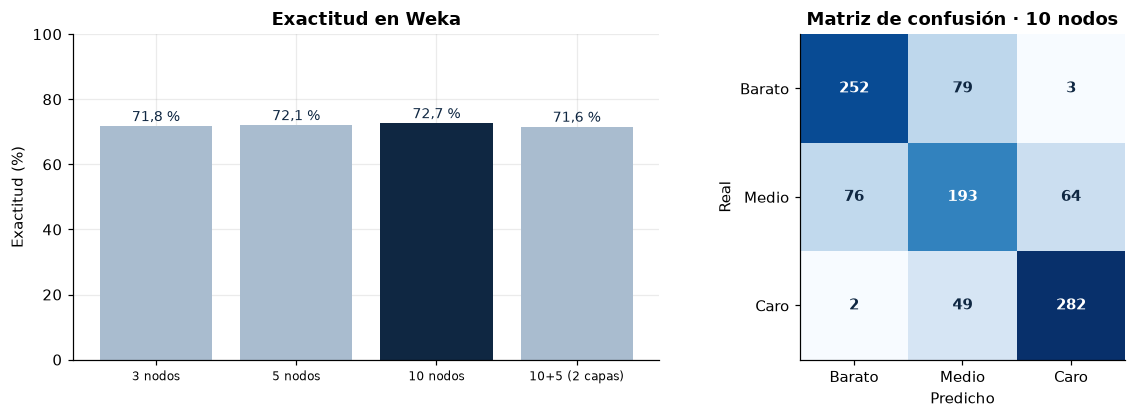

**Porcentaje de aciertos por segmento:**

,Barato,Medio,Caro
3,72.2 %,61.9 %,81.4 %
5,74.6 %,53.8 %,88.0 %
10,75.4 %,58.0 %,84.7 %
"10,5",75.4 %,55.3 %,84.1 %


Confusiones Barato↔Caro en la mejor configuración: 5 de 1000


In [33]:
mejor_w = weka["Accuracy (%)"].idxmax()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.3, 1]})
etq = [f"{h} nodos" if "," not in h else f"{h.replace(',', '+')} (2 capas)" for h in weka["hiddenLayers"]]
a1.bar(etq, weka["Accuracy (%)"], color=[MARINO if i == mejor_w else CLARO for i in weka.index])
for i, v in enumerate(weka["Accuracy (%)"]):
    a1.text(i, v + 1.5, num(v, 1) + " %", ha="center", fontsize=9, color=MARINO)
a1.set_ylim(0, 100); a1.set_title("Exactitud en Weka"); a1.set_ylabel("Exactitud (%)"); a1.tick_params(axis="x", labelsize=8)

m = matriz_weka(weka.loc[mejor_w])
a2.imshow(m, cmap="Blues"); a2.grid(False)
for i in range(3):
    for j in range(3):
        a2.text(j, i, m[i, j], ha="center", va="center", fontweight="bold",
                color="white" if m[i, j] > m.max() / 2 else MARINO)
a2.set_xticks(range(3), SEGMENTOS); a2.set_yticks(range(3), SEGMENTOS)
a2.set_xlabel("Predicho"); a2.set_ylabel("Real"); a2.set_title(f"Matriz de confusión · {weka.loc[mejor_w, 'hiddenLayers']} nodos")
plt.tight_layout(); plt.show()

aciertos = pd.DataFrame({h: np.diag(matriz_weka(f)) / matriz_weka(f).sum(axis=1) * 100
                         for h, f in zip(weka["hiddenLayers"], [r for _, r in weka.iterrows()])}, index=SEGMENTOS).T
display(Markdown("**Porcentaje de aciertos por segmento:**"))
display(aciertos.style.format("{:.1f} %"))
print(f"Confusiones Barato↔Caro en la mejor configuración: {m[0, 2] + m[2, 0]} de {m.sum()}")

### 6.3 Comparación justa con la red neuronal de Python

La red de Python predice el **precio exacto**, no el segmento. Para compararlas, los precios que estimó la red de Python en los 200 vehículos de prueba se **agrupan en los mismos tres segmentos** y se mide cuántos caen en el segmento correcto.

In [34]:
segmentar = lambda v: pd.cut(v, bins=[-np.inf, cortes[1], cortes[2], np.inf], labels=SEGMENTOS, right=False)
seg_real, seg_python = segmentar(y_te.values), segmentar(pred)
exactitud_python = (np.asarray(seg_real) == np.asarray(seg_python)).mean() * 100
display(pd.crosstab(pd.Series(seg_real, name="Real"), pd.Series(seg_python, name="Predicho (Python)")))
display(pd.DataFrame({"Red neuronal": ["Weka (10 nodos, sin variable modelo)", f"Python ({elegida} nodos, precio agrupado)"],
                      "Exactitud por segmento": [num(weka['Accuracy (%)'].max(), 1) + " %", num(exactitud_python, 1) + " %"]}))
comparar("Exactitud por segmento · red de Python (%)", exactitud_python, 94.5, tol=0.001)

Predicho (Python),Barato,Medio,Caro
Real,,,
Barato,63,3,0
Medio,3,56,1
Caro,0,4,70


,Red neuronal,Exactitud por segmento
0,"Weka (10 nodos, sin variable modelo)","72,7 %"
1,"Python (20 nodos, precio agrupado)","94,5 %"


✔ coincide | Exactitud por segmento · red de Python (%): recalculada 94,5000 · registrada 94,5000


**Conclusión de la sección.** En Weka la mejor red tuvo **10 nodos** y una exactitud de **72,70 %**; las diferencias entre configuraciones fueron pequeñas, y con 20 nodos el entrenamiento no terminó dentro del límite de tiempo. La red casi nunca confunde un carro barato con uno caro, y el segmento medio es el más difícil. La red de Python, agrupada en los mismos segmentos, acierta mucho más (94,5 %) porque usa la variable *modelo* y aprende el precio exacto. Esto completa el **objetivo específico 2** en su parte de Weka.

# 7. Uso del modelo final

**Objetivo de la sección.** Usar el modelo **publicado** (`modelo/modelo_ideale.joblib`, el mismo que carga la aplicación) para valorar vehículos concretos y ver cómo reacciona a cambios en el año y el kilometraje.

### 7.1 Carga del modelo de la aplicación y vehículos de ejemplo

In [35]:
modelo_app = joblib.load(ARCHIVOS["Modelo entrenado"])
catalogo = json.loads(ARCHIVOS["Catálogo del modelo"].read_text(encoding="utf-8"))
print(f"Modelo activo: {catalogo['mejor_modelo']} ({catalogo.get('nodos_red_neuronal', '?')} nodos) · "
      f"entrenado el {catalogo.get('fecha_entrenamiento', 'sin fecha')}")

def valorar(marca, modelo, anio, km, combustible, transmision, estado, margen=0.10):
    X = pd.DataFrame([{"marca": marca, "modelo": modelo, "combustible": combustible, "transmision": transmision,
                       "estado": estado, "antiguedad": ANIO_ACTUAL - anio, "kilometraje": km}])
    valor = float(modelo_app.predict(X)[0])
    return valor, valor * (1 - margen), valor * (1 + margen)

casos = [("Toyota", "Corolla", 2018, 120_000, "Gasolina", "Automatico", "Buen estado"),
         ("Chevrolet", "Spark", 2015, 110_000, "Gasolina", "Manual", "Medio estado"),
         ("Mazda", "CX-5", 2023, 30_000, "Gasolina", "Automatico", "Buen estado"),
         ("Toyota", "Hilux", 2020, 90_000, "Diesel", "Manual", "Segunda mano"),
         ("Renault", "Logan", 2012, 180_000, "Gasolina", "Manual", "Mal estado")]
filas = []
for c in casos:
    v, compra, venta = valorar(*c)
    filas.append({"Vehículo": f"{c[0]} {c[1]} {c[2]}", "Km": num(c[3], 0), "Estado": c[6],
                  "Valor estimado": pesos(v), "Compra (−10 %)": pesos(compra), "Venta (+10 %)": pesos(venta)})
display(pd.DataFrame(filas))

Modelo activo: Red neuronal (MLP) (20 nodos) · entrenado el 2026-11-03 11:12:16


,Vehículo,Km,Estado,Valor estimado,Compra (−10 %),Venta (+10 %)
0,Toyota Corolla 2018,120.000,Buen estado,$ 48.970.527,$ 44.073.474,$ 53.867.580
1,Chevrolet Spark 2015,110.000,Medio estado,$ 12.057.695,$ 10.851.926,$ 13.263.465
2,Mazda CX-5 2023,30.000,Buen estado,$ 125.364.344,$ 112.827.910,$ 137.900.778
3,Toyota Hilux 2020,90.000,Segunda mano,$ 124.194.347,$ 111.774.912,$ 136.613.782
4,Renault Logan 2012,180.000,Mal estado,$ 8.653.192,$ 7.787.873,$ 9.518.511


### 7.2 Sensibilidad: cómo cambia el precio con el kilometraje y el año

**Qué muestra:** el valor estimado de un **Toyota Corolla** en buen estado cuando se cambia una sola variable a la vez: el kilometraje (izquierda) y el año (derecha). **Por qué curvas:** muestran la respuesta del modelo de forma continua, como lo vería un usuario al mover los controles de la aplicación. **Qué respalda:** que el modelo aprendió un comportamiento **lógico**: más kilómetros o más años implican un precio menor, de forma suave y sin saltos extraños.

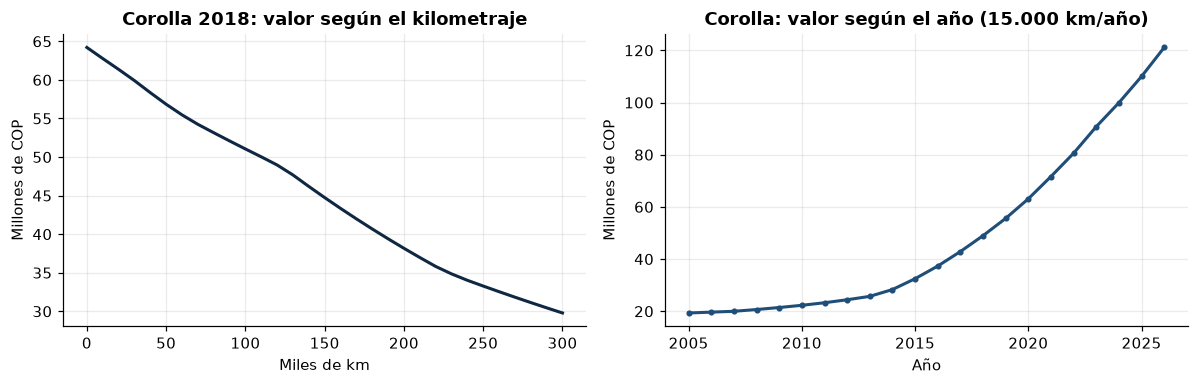

Corolla 2018 con 0 km: 64,2 M · con 300.000 km: 29,8 M


In [36]:
kms = np.arange(0, 300_001, 10_000)
anios = np.arange(2005, ANIO_ACTUAL + 1)
v_km = [valorar("Toyota", "Corolla", 2018, k, "Gasolina", "Automatico", "Buen estado")[0] for k in kms]
v_anio = [valorar("Toyota", "Corolla", a, 15_000 * (ANIO_ACTUAL - a), "Gasolina", "Automatico", "Buen estado")[0] for a in anios]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(kms / 1000, np.array(v_km) / 1e6, color=MARINO, lw=2)
a1.set_title("Corolla 2018: valor según el kilometraje"); a1.set_xlabel("Miles de km"); a1.set_ylabel("Millones de COP")
a2.plot(anios, np.array(v_anio) / 1e6, color=AZUL, lw=2, marker="o", ms=3)
a2.set_title("Corolla: valor según el año (15.000 km/año)"); a2.set_xlabel("Año"); a2.set_ylabel("Millones de COP")
plt.tight_layout(); plt.show()
print(f"Corolla 2018 con 0 km: {millones(v_km[0], 1)} · con 300.000 km: {millones(v_km[-1], 1)}")

### 7.3 Validaciones de coherencia de la aplicación

Antes de estimar el precio, la aplicación revisa que los datos tengan sentido. Se reproducen aquí las mismas reglas de `interfaz/pestana_valoracion.py` con tres casos de ejemplo.

In [37]:
from interfaz.pestana_valoracion import validar

pruebas = {
    "Nuevo 0 km pero con 50.000 km": {"anio": 2026, "kilometraje": 50_000, "estado": "Nuevo 0 km"},
    "Carro de 2024 con 400.000 km": {"anio": 2024, "kilometraje": 400_000, "estado": "Buen estado"},
    "Carro de 2010 con 500 km": {"anio": 2010, "kilometraje": 500, "estado": "Buen estado"},
    "Corolla 2018 con 120.000 km": {"anio": 2018, "kilometraje": 120_000, "estado": "Buen estado"},
}
filas = []
for nombre, d in pruebas.items():
    errores, avisos = validar(d, ANIO_ACTUAL)
    filas.append({"Caso": nombre, "Resultado": "Error: no estima" if errores else ("Aviso: sí estima" if avisos else "Correcto"),
                  "Mensaje": (errores or avisos or ["—"])[0]})
display(pd.DataFrame(filas))

2026-11-03 15:08:52.584 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-03 15:08:52.586 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-03 15:08:52.586 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


,Caso,Resultado,Mensaje
0,Nuevo 0 km pero con 50.000 km,Error: no estima,Un vehículo 'Nuevo 0 km' debe tener ~0 km y se...
1,Carro de 2024 con 400.000 km,Aviso: sí estima,El kilometraje es muy alto para la edad del ve...
2,Carro de 2010 con 500 km,Aviso: sí estima,Un vehículo de varios años con casi 0 km es po...
3,Corolla 2018 con 120.000 km,Correcto,—


**Conclusión de la sección.** El modelo que usa la aplicación entrega valores coherentes, sugiere la compra y la venta según el margen y responde de forma lógica a cambios de año y kilometraje. Las validaciones evitan estimar con datos incoherentes. Con esto se cumple el **objetivo específico 3**.

# 8. Resumen de resultados y comprobación de cifras

**Objetivo de la sección.** Reunir en una tabla todas las cifras que este cuaderno recalculó y compararlas con las registradas por el entrenamiento del proyecto, que son las que aparecen en el informe.

In [38]:
resumen = pd.DataFrame(COMPROBACIONES)
display(resumen.style.format({"Recalculada": lambda v: num(v, 4), "Registrada": lambda v: num(v, 4)}))
total, ok = len(resumen), int((resumen["Coincide"] == "✔").sum())
print(f"{ok} de {total} cifras coinciden con las del entrenamiento del proyecto.")

,Cifra,Recalculada,Registrada,Coincide
0,Precios reproducidos con la fórmula (de 1.000),"1.000,0000","1.000,0000",✔
1,R² validación cruzada · MLP 3 nodos,"0,9746","0,9746",✔
2,R² validación cruzada · MLP 5 nodos,"0,9754","0,9754",✔
3,R² validación cruzada · MLP 10 nodos,"0,9787","0,9787",✔
4,R² validación cruzada · MLP 20 nodos,"0,9818","0,9818",✔
5,R² validación cruzada · MLP 50 nodos,"0,9794","0,9794",✔
6,"R² validación cruzada · MLP 10,5 nodos","0,9798","0,9798",✔
7,"R² validación cruzada · MLP 20,10 nodos","0,9762","0,9762",✔
8,R² prueba · Red neuronal (MLP),"0,9791","0,9791",✔
9,MAE prueba · Red neuronal (MLP) (COP),"4.393.108,9070","4.393.108,9070",✔


23 de 23 cifras coinciden con las del entrenamiento del proyecto.


### Cifras principales del proyecto

In [39]:
fila_mejor = tabla.iloc[0]
display(pd.DataFrame({
    "Indicador": ["Vehículos del conjunto", "Mejor modelo", "R² en prueba", "Error promedio (MAE)",
                  "Vehículos con error < 20 %", "Red de Weka: mejor exactitud", "Red de Python agrupada en segmentos"],
    "Valor": [num(len(datos), 0), f"{fila_mejor['Modelo']} ({elegida} nodos)", num(fila_mejor["R2"], 3),
              pesos(fila_mejor["MAE (COP)"]), num((abs_pct < 20).mean() * 100, 1) + " %",
              num(weka["Accuracy (%)"].max(), 2) + " %", num(exactitud_python, 1) + " %"],
}))

,Indicador,Valor
0,Vehículos del conjunto,1.000
1,Mejor modelo,Red neuronal (MLP) (20 nodos)
2,R² en prueba,"0,979"
3,Error promedio (MAE),$ 4.393.109
4,Vehículos con error < 20 %,"95,0 %"
5,Red de Weka: mejor exactitud,"72,70 %"
6,Red de Python agrupada en segmentos,"94,5 %"


# 9. Limitaciones y trabajo futuro

* **Precios sintéticos.** El precio se generó con una fórmula (sección 3). Por eso las métricas son altas: con precios reales de mercado el error sería mayor, porque intervienen factores que no están en los datos (color, historial de accidentes, equipamiento, ciudad, temporada).
* **Variables faltantes.** El cilindraje y la potencia, previstos en la propuesta inicial, no estaban disponibles.
* **Weka Web.** El límite de 100 segundos obligó a retirar la variable *modelo* y a trabajar con segmentos, lo que reduce la información de la red de Weka.
* **Vehículos antiguos.** El error es mayor en los carros de más de 10 años; la compraventa debería revisarlos con más cuidado.
* **Uso responsable.** IDEALE es una **herramienta de apoyo**: la decisión final de compra o venta debe tomarla una persona después de revisar el vehículo.

**Trabajo futuro:** entrenar con precios reales del mercado colombiano, incorporar cilindraje, potencia y ciudad, y mostrar en la aplicación un **rango de precio** (por ejemplo, ± el error típico) en lugar de un único valor.

# 10. Conclusiones

**Respecto al objetivo general.** Se desarrolló IDEALE, un sistema que estima el valor comercial de un vehículo usado a partir de sus características y sugiere precios de compra y de venta según el margen de la empresa. El modelo final se equivoca en promedio alrededor de 4,4 millones de pesos y el 95 % de sus estimaciones tiene un error menor al 20 %.

**Respecto al objetivo específico 1.** Se preparó y analizó un conjunto de 1.000 vehículos de 10 marcas y 59 modelos, sin datos faltantes ni duplicados. Se identificaron como variables del valor la marca, el modelo, la antigüedad, el kilometraje, el combustible, la transmisión y el estado; se creó la antigüedad y se modeló el logaritmo del precio, decisiones que respaldan las gráficas de la sección 3.

**Respecto al objetivo específico 2.** Se entrenaron y compararon cuatro modelos. La red neuronal de 20 nodos fue la mejor, seguida de cerca por la regresión lineal, y ambas superaron ampliamente a la línea base. En Python y en Weka, más nodos o una segunda capa no mejoraron de forma clara; en Weka la mejor red (10 nodos) alcanzó 72,70 % de exactitud por segmento.

**Respecto al objetivo específico 3.** El modelo final se integró en la aplicación web: valida los datos, estima el valor, sugiere la compra y la venta y responde de forma lógica a cambios de año y kilometraje.

Todas las cifras de este cuaderno se **recalcularon** a partir de los datos y del código del proyecto, y coinciden con las del informe (sección 8).

# Anexo A. Glosario

| Término | Significado |
|---|---|
| **ARFF** | Formato de archivo de datos que usa Weka. |
| **CRISP-DM** | Metodología de proyectos de datos en seis fases: negocio, datos, preparación, modelado, evaluación e implementación. |
| **Época** | Una vuelta completa de la red neuronal por los datos de entrenamiento. |
| **Exactitud** | Porcentaje de vehículos clasificados en el segmento correcto. |
| **Línea base** | Modelo muy simple (siempre la mediana) que sirve de referencia mínima. |
| **MAE** | Error absoluto medio: cuántos pesos se equivoca el modelo en promedio. |
| **Matriz de confusión** | Tabla que cruza el segmento real con el predicho; la diagonal son los aciertos. |
| **MLP / red neuronal** | Perceptrón multicapa: capas de nodos que combinan las entradas con pesos y una función de activación (ReLU). |
| **Nodo** | Neurona de la capa oculta; más nodos dan más capacidad, pero también más riesgo de memorizar. |
| **One-hot** | Convertir una variable de texto en columnas de 0 y 1. |
| **Parada temprana** | Detener el entrenamiento cuando el error deja de mejorar, para evitar el sobreajuste. |
| **R²** | Proporción de la variación del precio que explica el modelo (1 = perfecto). |
| **Semilla** | Número fijo que hace que los resultados aleatorios se repitan igual. |
| **Sobreajuste** | Cuando el modelo memoriza los datos de entrenamiento y falla con datos nuevos. |
| **Validación cruzada** | Entrenar y probar varias veces con distintas particiones para comprobar que el resultado es estable. |